# Gemma3 vs Gemini Performance Analysis
## Step-by-Step Debugging for Tau-Bench

This notebook provides a comprehensive analysis of the performance gap between Gemma3:12B and Gemini-2.5-flash-lite in the tau-bench environment.

---

## 1. Environment Setup & GPU Check

First, let's verify our environment and GPU availability.

In [1]:
import os
import sys
import json
import time
import logging
import traceback
from datetime import datetime
from typing import Dict, Any, List

# Try importing optional packages
try:
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    print("✅ Data science packages available")
except ImportError as e:
    print(f"⚠️ Some packages missing: {e}")
    print("💡 You can install with: pip install pandas matplotlib seaborn")

# Setup logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

print("🔧 Environment Setup (Using Current 'tau' Environment)")
print(f"Python version: {sys.version}")
print(f"Python executable: {sys.executable}")
print(f"Working directory: {os.getcwd()}")
print(f"Current time: {datetime.now()}")
print("✅ Using your existing tau environment!")

✅ Data science packages available
🔧 Environment Setup (Using Current 'tau' Environment)
Python version: 3.11.7 (main, Dec 15 2023, 18:12:31) [GCC 11.2.0]
Python executable: /home/lixali_google_com/data/anaconda3/bin/python
Working directory: /home/lixali_google_com/data/adk-lightning/tau-bench-lightning
Current time: 2025-09-15 18:56:48.095793
✅ Using your existing tau environment!


In [2]:
# Check GPU availability
try:
    import torch
    print(f"🎯 GPU Information:")
    print(f"CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"GPU count: {torch.cuda.device_count()}")
        for i in range(torch.cuda.device_count()):
            gpu_name = torch.cuda.get_device_name(i)
            gpu_memory = torch.cuda.get_device_properties(i).total_memory / 1e9
            print(f"  GPU {i}: {gpu_name} ({gpu_memory:.1f} GB)")
except ImportError:
    print("⚠️ PyTorch not available - GPU info unavailable")

🎯 GPU Information:
CUDA available: True
GPU count: 8
  GPU 0: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 1: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 2: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 3: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 4: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 5: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 6: NVIDIA H100 80GB HBM3 (84.9 GB)
  GPU 7: NVIDIA H100 80GB HBM3 (84.9 GB)


In [3]:
# Ensure we're in the tau-bench directory and add to path
current_dir = os.getcwd()
print(f"📂 Current directory: {current_dir}")

# Add current directory to path (since you're already in tau-bench-lightning)
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

# Import tau-bench modules
try:
    from tau_bench.model_utils.model.gemma import GemmaModel
    from tau_bench.model_utils.model.chat import Message, Role
    from tau_bench.envs.retail.tasks_test import TASKS_TEST
    from litellm import completion
    print("✅ Tau-bench imports successful")
    print(f"✅ LiteLLM version: {completion.__module__}")
    print(f"✅ Found {len(TASKS_TEST)} test tasks")
except ImportError as e:
    print(f"❌ Import error: {e}")
    print("🔍 Let's check what's available...")
    # Show available modules
    for item in os.listdir('.'):
        if os.path.isdir(item) and not item.startswith('.'):
            print(f"  📁 {item}")
    print("\n💡 Make sure you're in the tau-bench-lightning directory")

📂 Current directory: /home/lixali_google_com/data/adk-lightning/tau-bench-lightning
✅ Tau-bench imports successful
✅ LiteLLM version: litellm.main
✅ Found 115 test tasks


## 2. Check Infrastructure Status

Let's verify both Ollama (for Gemma3) and Vertex AI (for Gemini) are working.

In [4]:
# Check Ollama server status
import requests

def check_ollama_status():
    try:
        response = requests.get("http://localhost:11434/api/tags", timeout=5)
        if response.status_code == 200:
            models = response.json().get('models', [])
            print("✅ Ollama server is running")
            print(f"Available models: {len(models)}")
            for model in models:
                print(f"  - {model.get('name', 'unknown')}")
            return True
        else:
            print(f"❌ Ollama server returned status {response.status_code}")
            return False
    except Exception as e:
        print(f"❌ Ollama server not accessible: {e}")
        print("💡 Try running: ollama serve")
        return False

ollama_available = check_ollama_status()

✅ Ollama server is running
Available models: 1
  - gemma3:12b


In [5]:
# Check Vertex AI access
def check_vertex_ai_status():
    try:
        # Test with a simple completion
        response = completion(
            model="gemini-2.5-flash-lite",
            custom_llm_provider="vertex_ai",
            messages=[{"role": "user", "content": "Say 'test'"}],
            temperature=0.0
        )
        print("✅ Vertex AI access working")
        print(f"Response: {response.choices[0].message.content}")
        return True
    except Exception as e:
        print(f"❌ Vertex AI access failed: {e}")
        print("💡 Try running: gcloud auth application-default login")
        return False

vertex_ai_available = check_vertex_ai_status()

18:56:55 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
INFO:LiteLLM:
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
18:56:56 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler


✅ Vertex AI access working
Response: test


## 3. Load Tau-Bench Test Data

Let's examine the actual tasks that will be used for testing.

In [6]:
# Load and examine tau-bench tasks
print(f"📋 Tau-Bench Test Data:")
print(f"Total test tasks: {len(TASKS_TEST)}")

# Show first task as example
sample_task = TASKS_TEST[0]
print(f"\n📝 Sample Task (ID: 0):")
print(f"User ID: {sample_task.user_id}")
print(f"Instruction: {sample_task.instruction[:200]}...")
print(f"Actions required: {len(sample_task.actions)}")

# Show action breakdown
print(f"\n🎯 Required Actions:")
for i, action in enumerate(sample_task.actions):
    print(f"  {i+1}. {action.name}")
    if action.kwargs:
        for key, value in action.kwargs.items():
            print(f"     {key}: {value}")

📋 Tau-Bench Test Data:
Total test tasks: 115

📝 Sample Task (ID: 0):
User ID: yusuf_rossi_9620
Instruction: You are Yusuf Rossi in 19122. You received your order #W2378156 and wish to exchange the mechanical keyboard for a similar one but with clicky switches and the smart thermostat for one compatible with...
Actions required: 5

🎯 Required Actions:
  1. find_user_id_by_name_zip
     first_name: Yusuf
     last_name: Rossi
     zip: 19122
  2. get_order_details
     order_id: #W2378156
  3. get_product_details
     product_id: 1656367028
  4. get_product_details
     product_id: 4896585277
  5. exchange_delivered_order_items
     order_id: #W2378156
     item_ids: ['1151293680', '4983901480']
     new_item_ids: ['7706410293', '7747408585']
     payment_method_id: credit_card_9513926


## 4. Model Initialization & Configuration

Now let's initialize both models and compare their configurations.

In [7]:
# Initialize Gemma3 model
gemma_model = None
if ollama_available:
    try:
        gemma_model = GemmaModel(
            model="gemma3:12b",
            provider="ollama",
            temperature=0.0
        )
        print("✅ Gemma3 model initialized")
        print(f"Model info: {gemma_model.get_model_info()}")
    except Exception as e:
        print(f"❌ Gemma3 initialization failed: {e}")
else:
    print("⏭️ Skipping Gemma3 - Ollama not available")

✅ Gemma3 model initialized
Model info: {'model': 'gemma3:12b', 'provider': 'ollama', 'model_path': None, 'base_url': None, 'effective_model_id': 'gemma3:12b'}


In [8]:
# Create Gemini wrapper for consistent interface
class GeminiWrapper:
    def __init__(self):
        self.model = "gemini-2.5-flash-lite"
        self.provider = "vertex_ai"
    
    def generate_message(self, messages: List[Message], force_json: bool, temperature: float = 0.0) -> Message:
        # Convert Message objects to dict format
        formatted_messages = []
        for msg in messages:
            formatted_messages.append({
                "role": msg.role.value,
                "content": msg.content
            })
        
        response = completion(
            model=self.model,
            custom_llm_provider=self.provider,
            messages=formatted_messages,
            temperature=temperature
        )
        
        return Message(role=Role.ASSISTANT, content=response.choices[0].message.content)
    
    def get_model_info(self):
        return {
            'model': self.model,
            'provider': self.provider,
            'deployment': 'vertex_ai_cloud'
        }

gemini_model = None
if vertex_ai_available:
    try:
        gemini_model = GeminiWrapper()
        print("✅ Gemini model initialized")
        print(f"Model info: {gemini_model.get_model_info()}")
    except Exception as e:
        print(f"❌ Gemini initialization failed: {e}")
else:
    print("⏭️ Skipping Gemini - Vertex AI not available")

✅ Gemini model initialized
Model info: {'model': 'gemini-2.5-flash-lite', 'provider': 'vertex_ai', 'deployment': 'vertex_ai_cloud'}


## 5. Prompt Analysis & Formatting

Let's examine how prompts are formatted for each model and ensure they're identical.

In [9]:
# Create test messages from tau-bench task
test_task = TASKS_TEST[0]

# Create realistic tau-bench messages
wiki_info = """You are a helpful assistant for a retail customer service environment. 
You have access to various tools to help customers with their orders, returns, and exchanges.
Always be polite and helpful."""

test_messages = [
    Message(role=Role.SYSTEM, content=wiki_info),
    Message(role=Role.USER, content=test_task.instruction)
]

print("📝 Test Messages Created:")
for i, msg in enumerate(test_messages):
    print(f"\nMessage {i+1} ({msg.role.value}):")
    content_preview = msg.content[:200] + "..." if len(msg.content) > 200 else msg.content
    print(f"{content_preview}")

📝 Test Messages Created:

Message 1 (system):
You are a helpful assistant for a retail customer service environment. 
You have access to various tools to help customers with their orders, returns, and exchanges.
Always be polite and helpful.

Message 2 (user):
You are Yusuf Rossi in 19122. You received your order #W2378156 and wish to exchange the mechanical keyboard for a similar one but with clicky switches and the smart thermostat for one compatible with...


In [10]:
# Show formatted messages for each model
if gemma_model:
    gemma_formatted = gemma_model.build_generate_message_state(test_messages)
    print("🔍 Gemma3 Formatted Messages:")
    print(json.dumps(gemma_formatted, indent=2))
else:
    print("⏭️ Gemma3 formatting skipped - model not available")

print("\n" + "="*50)

if gemini_model:
    # Simulate Gemini formatting (same as Gemma)
    gemini_formatted = []
    for msg in test_messages:
        gemini_formatted.append({
            "role": msg.role.value,
            "content": msg.content
        })
    print("🔍 Gemini Formatted Messages:")
    print(json.dumps(gemini_formatted, indent=2))
else:
    print("⏭️ Gemini formatting skipped - model not available")

# Verify they're identical
if gemma_model and gemini_model:
    if gemma_formatted == gemini_formatted:
        print("\n✅ CONFIRMED: Both models receive identical prompts")
    else:
        print("\n❌ WARNING: Prompt formatting differs between models")

🔍 Gemma3 Formatted Messages:
[
  {
    "role": "system",
    "content": "You are a helpful assistant for a retail customer service environment. \nYou have access to various tools to help customers with their orders, returns, and exchanges.\nAlways be polite and helpful."
  },
  {
    "role": "user",
    "content": "You are Yusuf Rossi in 19122. You received your order #W2378156 and wish to exchange the mechanical keyboard for a similar one but with clicky switches and the smart thermostat for one compatible with Google Home instead of Apple HomeKit. If there is no keyboard that is clicky, RGB backlight, full size, you'd go for no backlight. You are detail-oriented and want to make sure everything is addressed in one go."
  }
]

🔍 Gemini Formatted Messages:
[
  {
    "role": "system",
    "content": "You are a helpful assistant for a retail customer service environment. \nYou have access to various tools to help customers with their orders, returns, and exchanges.\nAlways be polite and 

## 6. Step-by-Step Inference Comparison

Now let's run the same prompt through both models and compare responses in detail.

In [11]:
# Performance tracking
results = {
    "timestamp": datetime.now().isoformat(),
    "test_case": "tau_bench_retail_task_0",
    "gemma_result": {},
    "gemini_result": {}
}

print("🚀 Starting Step-by-Step Inference...")
print(f"Task: {test_task.instruction[:100]}...")
print("\n" + "="*60)

🚀 Starting Step-by-Step Inference...
Task: You are Yusuf Rossi in 19122. You received your order #W2378156 and wish to exchange the mechanical ...



In [12]:
# Test Gemma3
print("🔄 Testing Gemma3...")

if gemma_model:
    try:
        start_time = time.time()
        
        print("  📤 Sending request to Ollama...")
        gemma_response = gemma_model.generate_message(
            test_messages, 
            force_json=False,
            temperature=0.0
        )
        
        end_time = time.time()
        inference_time = end_time - start_time
        
        results["gemma_result"] = {
            "success": True,
            "response_length": len(gemma_response.content),
            "inference_time": inference_time,
            "response_preview": gemma_response.content[:300],
            "full_response": gemma_response.content
        }
        
        print(f"  ✅ Success! Response length: {len(gemma_response.content)} chars")
        print(f"  ⏱️ Inference time: {inference_time:.2f} seconds")
        print(f"  📝 Response preview:")
        print(f"     {gemma_response.content[:]}...")
        
    except Exception as e:
        results["gemma_result"] = {
            "success": False,
            "error": str(e),
            "traceback": traceback.format_exc()
        }
        print(f"  ❌ Error: {e}")
        print(f"  🔍 This confirms the infrastructure issues we identified")
else:
    print("  ⏭️ Skipped - Gemma3 not available")
    results["gemma_result"] = {"success": False, "error": "Model not available"}

18:57:31 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemma3:12b; provider = ollama
INFO:LiteLLM:
LiteLLM completion() model= gemma3:12b; provider = ollama


🔄 Testing Gemma3...
  📤 Sending request to Ollama...


18:57:48 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler


  ✅ Success! Response length: 2225 chars
  ⏱️ Inference time: 17.23 seconds
  📝 Response preview:
     Okay, Mr. Rossi, thank you for contacting us! My name is Yusuf Rossi, and I'll be happy to assist you with your exchange for order #W2378156. Let's get everything sorted out for you in one go.

Just to confirm, you'd like to exchange two items:

1.  **Mechanical Keyboard:** You'd like to exchange this for a similar model, but with clicky switches. Ideally, you're looking for a full-size keyboard with RGB backlighting. However, if a clicky, full-size keyboard with RGB isn't available, you're happy to forgo the RGB backlight.
2.  **Smart Thermostat:** You'd like to exchange this for a model compatible with Google Home instead of Apple HomeKit.

Let me check our current inventory to see what options we have available for both of these items. I'm going to pull up the details of your original order now to ensure we're both on the same page regarding the original items.

**(Pause while chec

In [13]:
# Test Gemini
print("\n🔄 Testing Gemini...")

if gemini_model:
    try:
        start_time = time.time()
        
        print("  📤 Sending request to Vertex AI...")
        gemini_response = gemini_model.generate_message(
            test_messages, 
            force_json=False,
            temperature=0.0
        )
        
        end_time = time.time()
        inference_time = end_time - start_time
        
        results["gemini_result"] = {
            "success": True,
            "response_length": len(gemini_response.content),
            "inference_time": inference_time,
            "response_preview": gemini_response.content[:300],
            "full_response": gemini_response.content
        }
        
        print(f"  ✅ Success! Response length: {len(gemini_response.content)} chars")
        print(f"  ⏱️ Inference time: {inference_time:.2f} seconds")
        print(f"  📝 Response preview:")
        print(f"     {gemini_response.content[:]}...")
        
    except Exception as e:
        results["gemini_result"] = {
            "success": False,
            "error": str(e),
            "traceback": traceback.format_exc()
        }
        print(f"  ❌ Error: {e}")
else:
    print("  ⏭️ Skipped - Gemini not available")
    results["gemini_result"] = {"success": False, "error": "Model not available"}

18:57:48 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
INFO:LiteLLM:
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai



🔄 Testing Gemini...
  📤 Sending request to Vertex AI...


18:57:49 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler


  ✅ Success! Response length: 1102 chars
  ⏱️ Inference time: 1.25 seconds
  📝 Response preview:
     Hello Yusuf! Thank you for reaching out to us. I'm happy to help you with your exchange for order #W2378156.

Let's get this sorted out for you.

**For your mechanical keyboard exchange:**

You're looking for a similar mechanical keyboard, but with **clicky switches**. You also specified that it should be **full-size** and have an **RGB backlight**. If a full-size, clicky, RGB backlit keyboard isn't available, you'd prefer one with **no backlight**.

I will check our current inventory for a full-size mechanical keyboard with clicky switches and an RGB backlight. If that's not available, I'll look for a full-size, clicky keyboard with no backlight.

**For your smart thermostat exchange:**

You'd like to exchange the smart thermostat for one that is **compatible with Google Home** instead of Apple HomeKit.

I will find a smart thermostat in our selection that supports Google Home integra

## 6.5. Multi-Turn Conversation with Tool Calling Analysis

Now let's create a realistic multi-turn conversation that involves tool calling to understand exactly how each model handles:
1. **Tool detection** - Does the model understand when to use tools?
2. **Tool calling format** - Does it format tool calls correctly?
3. **Tool response processing** - Can it use tool results in follow-up responses?
4. **Conversation continuity** - Does it maintain context across turns?

In [14]:
# Define realistic retail tools for multi-turn conversation
retail_tools = [
    {
        "type": "function",
        "function": {
            "name": "get_order_status",
            "description": "Get the current status of a customer order",
            "parameters": {
                "type": "object",
                "properties": {
                    "order_id": {
                        "type": "string",
                        "description": "The order ID to check"
                    }
                },
                "required": ["order_id"]
            }
        }
    },
    {
        "type": "function", 
        "function": {
            "name": "initiate_return",
            "description": "Start the return process for an item",
            "parameters": {
                "type": "object",
                "properties": {
                    "order_id": {
                        "type": "string",
                        "description": "The order ID containing the item to return"
                    },
                    "item_name": {
                        "type": "string",
                        "description": "Name of the item to return"
                    },
                    "reason": {
                        "type": "string", 
                        "description": "Reason for return"
                    }
                },
                "required": ["order_id", "item_name", "reason"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "check_exchange_options",
            "description": "Check available exchange options for an item", 
            "parameters": {
                "type": "object",
                "properties": {
                    "item_name": {
                        "type": "string",
                        "description": "Name of the item to exchange"
                    },
                    "preferred_size": {
                        "type": "string",
                        "description": "Preferred size for exchange"
                    }
                },
                "required": ["item_name"]
            }
        }
    }
]

print("🔧 Tool Definitions Created:")
for i, tool in enumerate(retail_tools):
    print(f"  {i+1}. {tool['function']['name']}: {tool['function']['description']}")

# Mock tool execution function
def execute_tool(tool_name, arguments):
    """Simulate tool execution with realistic responses"""
    if tool_name == "get_order_status":
        return {
            "order_id": arguments["order_id"],
            "status": "Delivered",
            "delivery_date": "2024-09-10",
            "items": [
                {"name": "Wireless Keyboard", "status": "Delivered"},
                {"name": "Smart Thermostat", "status": "Delivered"}
            ]
        }
    elif tool_name == "initiate_return":
        return {
            "return_id": "RET789123",
            "status": "Return initiated",
            "return_label": "Print label at: https://returns.example.com/RET789123",
            "estimated_refund": "$89.99"
        }
    elif tool_name == "check_exchange_options":
        return {
            "available_sizes": ["Medium", "Large", "XL"],
            "in_stock": True,
            "exchange_fee": "$0.00",
            "estimated_ship_date": "2024-09-18"
        }
    else:
        return {"error": f"Unknown tool: {tool_name}"}

🔧 Tool Definitions Created:
  1. get_order_status: Get the current status of a customer order
  2. initiate_return: Start the return process for an item
  3. check_exchange_options: Check available exchange options for an item


In [15]:
# Multi-turn conversation setup
conversation_scenario = {
    "customer_name": "Alex Chen",
    "order_id": "#W2378156", 
    "issue": "Customer wants to exchange a wireless keyboard for a different size and return a smart thermostat that's not working"
}

# Create multi-turn conversation messages
system_prompt = """You are a helpful customer service agent for RetailCorp. You have access to tools to help customers with orders, returns, and exchanges. 

Available tools:
- get_order_status: Check order details and delivery status
- initiate_return: Start return process for defective items  
- check_exchange_options: Find exchange options for sizing issues

Always be polite, efficient, and use tools when needed to help customers."""

# Turn 1: Initial customer request
turn1_user = """Hi, I have an issue with my recent order #W2378156. I received a wireless keyboard but it's too small for my hands, and the smart thermostat isn't working properly. Can you help me exchange the keyboard for a larger size and return the broken thermostat?"""

conversation_history = [
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": turn1_user}
]

print("🎭 Multi-Turn Conversation Scenario:")
print(f"Customer: {conversation_scenario['customer_name']}")
print(f"Order ID: {conversation_scenario['order_id']}")
print(f"Issue: {conversation_scenario['issue']}")
print(f"\n💬 Initial Request:")
print(f"'{turn1_user[:100]}...'")
print("\n" + "="*80)

🎭 Multi-Turn Conversation Scenario:
Customer: Alex Chen
Order ID: #W2378156
Issue: Customer wants to exchange a wireless keyboard for a different size and return a smart thermostat that's not working

💬 Initial Request:
'Hi, I have an issue with my recent order #W2378156. I received a wireless keyboard but it's too smal...'



In [16]:
def run_multi_turn_conversation(model, model_name, conversation_history, max_turns=5):
    """Run a complete multi-turn conversation with detailed analysis"""
    
    print(f"\n🤖 Starting Multi-Turn Conversation with {model_name}")
    print("="*60)
    
    conversation_log = {
        "model": model_name,
        "turns": [],
        "tool_calls": [],
        "errors": [],
        "analysis": {}
    }
    
    current_history = conversation_history.copy()
    
    for turn in range(max_turns):
        print(f"\n📍 TURN {turn + 1}")
        print("-" * 30)
        
        try:
            # Convert to LiteLLM format
            litellm_messages = []
            for msg in current_history:
                if isinstance(msg, dict):
                    litellm_messages.append(msg)
                else:
                    litellm_messages.append({
                        "role": msg.role.value if hasattr(msg, 'role') else msg['role'],
                        "content": msg.content if hasattr(msg, 'content') else msg['content']
                    })
            
            print(f"📤 Sending {len(litellm_messages)} messages to {model_name}...")
            
            # Make the API call with tools
            if model_name == "Gemma3":
                # Gemma3 via Ollama
                response = completion(
                    model="gemma3:12b",
                    custom_llm_provider="ollama",
                    messages=litellm_messages,
                    tools=retail_tools,
                    temperature=0.0
                )
            else:
                # Gemini via Vertex AI
                response = completion(
                    model="gemini-2.5-flash-lite",
                    custom_llm_provider="vertex_ai", 
                    messages=litellm_messages,
                    tools=retail_tools,
                    temperature=0.0
                )
            
            # Extract response
            assistant_message = response.choices[0].message
            
            print(f"📥 Response received:")
            print(f"   Content length: {len(assistant_message.content or '') if assistant_message.content else 0} chars")
            
            # Check for tool calls
            tool_calls = getattr(assistant_message, 'tool_calls', None)
            
            if tool_calls:
                print(f"   🔧 Tool calls detected: {len(tool_calls)}")
                
                # Process each tool call
                for i, tool_call in enumerate(tool_calls):
                    print(f"\n   🔧 Tool Call {i+1}:")
                    print(f"      Function: {tool_call.function.name}")
                    print(f"      Arguments: {tool_call.function.arguments}")
                    
                    # Parse arguments
                    try:
                        args = json.loads(tool_call.function.arguments)
                        print(f"      Parsed args: {args}")
                        
                        # Execute tool
                        tool_result = execute_tool(tool_call.function.name, args)
                        print(f"      Tool result: {tool_result}")
                        
                        # Log tool call
                        conversation_log["tool_calls"].append({
                            "turn": turn + 1,
                            "function": tool_call.function.name,
                            "arguments": args,
                            "result": tool_result
                        })
                        
                        # Add tool result to conversation - FIXED SYNTAX ERROR
                        current_history.append({
                            "role": "assistant",
                            "content": assistant_message.content,
                            "tool_calls": [{
                                "id": tool_call.id,
                                "type": "function",
                                "function": {
                                    "name": tool_call.function.name,
                                    "arguments": tool_call.function.arguments
                                }
                            }]
                        })
                        current_history.append({
                            "role": "tool",
                            "content": json.dumps(tool_result),
                            "tool_call_id": tool_call.id
                        })
                        
                    except json.JSONDecodeError as e:
                        print(f"      ❌ JSON parsing error: {e}")
                        conversation_log["errors"].append(f"Turn {turn+1}: JSON parse error - {e}")
                        
            else:
                print(f"   💬 Text response only")
                current_history.append({
                    "role": "assistant", 
                    "content": assistant_message.content
                })
            
            # Display the response content
            if assistant_message.content:
                print(f"\n💬 Assistant Response:")
                print(f"   {assistant_message.content[:200]}...")
            
            # Log turn
            conversation_log["turns"].append({
                "turn": turn + 1,
                "response_content": assistant_message.content,
                "tool_calls_count": len(tool_calls) if tool_calls else 0,
                "response_length": len(assistant_message.content) if assistant_message.content else 0
            })
            
            # Check if conversation should continue
            if not tool_calls and turn > 0:
                print(f"\n✅ Conversation completed at turn {turn + 1}")
                break
                
            # Add follow-up user message if there were tool calls
            if tool_calls and turn < max_turns - 1:
                followup_message = "Thank you! Could you also help me understand the timeline for these processes?"
                current_history.append({"role": "user", "content": followup_message})
                print(f"\n👤 User follow-up: {followup_message}")
                
        except Exception as e:
            print(f"\n❌ Error in turn {turn + 1}: {e}")
            conversation_log["errors"].append(f"Turn {turn+1}: {str(e)}")
            break
    
    # Final analysis
    total_tools = len(conversation_log["tool_calls"])
    total_turns = len(conversation_log["turns"])
    
    conversation_log["analysis"] = {
        "total_turns": total_turns,
        "total_tool_calls": total_tools,
        "tool_success_rate": (total_tools / max(total_turns, 1)) * 100,
        "avg_response_length": sum(t["response_length"] for t in conversation_log["turns"]) / max(total_turns, 1),
        "error_count": len(conversation_log["errors"])
    }
    
    print(f"\n📊 Conversation Summary:")
    print(f"   Turns completed: {total_turns}")
    print(f"   Tool calls made: {total_tools}")
    print(f"   Errors encountered: {len(conversation_log['errors'])}")
    print(f"   Avg response length: {conversation_log['analysis']['avg_response_length']:.1f} chars")
    
    return conversation_log

In [17]:
# Run multi-turn conversation with Gemma3
print("🟡 TESTING GEMMA3 MULTI-TURN CONVERSATION")
print("="*80)

gemma_conversation_log = None
if ollama_available:
    try:
        gemma_conversation_log = run_multi_turn_conversation(
            model=None,  # We'll use direct API calls
            model_name="Gemma3",
            conversation_history=conversation_history,
            max_turns=3
        )
    except Exception as e:
        print(f"❌ Gemma3 multi-turn conversation failed: {e}")
        print(f"🔍 This likely confirms infrastructure issues")
        gemma_conversation_log = {
            "model": "Gemma3",
            "error": str(e),
            "analysis": {"total_turns": 0, "total_tool_calls": 0, "error_count": 1}
        }
else:
    print("⏭️ Skipping Gemma3 - Ollama not available")
    gemma_conversation_log = {
        "model": "Gemma3", 
        "error": "Ollama not available",
        "analysis": {"total_turns": 0, "total_tool_calls": 0, "error_count": 1}
    }

18:58:39 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemma3:12b; provider = ollama
INFO:LiteLLM:
LiteLLM completion() model= gemma3:12b; provider = ollama


🟡 TESTING GEMMA3 MULTI-TURN CONVERSATION

🤖 Starting Multi-Turn Conversation with Gemma3

📍 TURN 1
------------------------------
📤 Sending 2 messages to Gemma3...


18:58:40 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler
18:58:40 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemma3:12b; provider = ollama
INFO:LiteLLM:
LiteLLM completion() model= gemma3:12b; provider = ollama


📥 Response received:
   Content length: 0 chars
   🔧 Tool calls detected: 1

   🔧 Tool Call 1:
      Function: check_exchange_options
      Arguments: {"item_name": "wireless keyboard", "preferred_size": "larger"}
      Parsed args: {'item_name': 'wireless keyboard', 'preferred_size': 'larger'}
      Tool result: {'available_sizes': ['Medium', 'Large', 'XL'], 'in_stock': True, 'exchange_fee': '$0.00', 'estimated_ship_date': '2024-09-18'}

👤 User follow-up: Thank you! Could you also help me understand the timeline for these processes?

📍 TURN 2
------------------------------
📤 Sending 5 messages to Gemma3...


18:58:41 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler
18:58:41 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemma3:12b; provider = ollama
INFO:LiteLLM:
LiteLLM completion() model= gemma3:12b; provider = ollama


📥 Response received:
   Content length: 0 chars
   🔧 Tool calls detected: 1

   🔧 Tool Call 1:
      Function: check_exchange_options
      Arguments: {"item_name": "wireless keyboard"}
      Parsed args: {'item_name': 'wireless keyboard'}
      Tool result: {'available_sizes': ['Medium', 'Large', 'XL'], 'in_stock': True, 'exchange_fee': '$0.00', 'estimated_ship_date': '2024-09-18'}

👤 User follow-up: Thank you! Could you also help me understand the timeline for these processes?

📍 TURN 3
------------------------------
📤 Sending 8 messages to Gemma3...


18:58:42 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler


📥 Response received:
   Content length: 0 chars
   🔧 Tool calls detected: 1

   🔧 Tool Call 1:
      Function: get_order_status
      Arguments: {"order_id": "W2378156"}
      Parsed args: {'order_id': 'W2378156'}
      Tool result: {'order_id': 'W2378156', 'status': 'Delivered', 'delivery_date': '2024-09-10', 'items': [{'name': 'Wireless Keyboard', 'status': 'Delivered'}, {'name': 'Smart Thermostat', 'status': 'Delivered'}]}

📊 Conversation Summary:
   Turns completed: 3
   Tool calls made: 3
   Errors encountered: 0
   Avg response length: 0.0 chars


In [18]:
# Run multi-turn conversation with Gemini
print("\n🔵 TESTING GEMINI MULTI-TURN CONVERSATION")
print("="*80)

gemini_conversation_log = None
if vertex_ai_available:
    try:
        gemini_conversation_log = run_multi_turn_conversation(
            model=None,  # We'll use direct API calls
            model_name="Gemini",
            conversation_history=conversation_history,
            max_turns=3
        )
    except Exception as e:
        print(f"❌ Gemini multi-turn conversation failed: {e}")
        gemini_conversation_log = {
            "model": "Gemini",
            "error": str(e),
            "analysis": {"total_turns": 0, "total_tool_calls": 0, "error_count": 1}
        }
else:
    print("⏭️ Skipping Gemini - Vertex AI not available")
    gemini_conversation_log = {
        "model": "Gemini",
        "error": "Vertex AI not available", 
        "analysis": {"total_turns": 0, "total_tool_calls": 0, "error_count": 1}
    }

18:59:35 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
INFO:LiteLLM:
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai



🔵 TESTING GEMINI MULTI-TURN CONVERSATION

🤖 Starting Multi-Turn Conversation with Gemini

📍 TURN 1
------------------------------
📤 Sending 2 messages to Gemini...


18:59:36 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler
18:59:36 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
INFO:LiteLLM:
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai


📥 Response received:
   Content length: 0 chars
   🔧 Tool calls detected: 2

   🔧 Tool Call 1:
      Function: check_exchange_options
      Arguments: {"preferred_size": "large", "item_name": "wireless keyboard"}
      Parsed args: {'preferred_size': 'large', 'item_name': 'wireless keyboard'}
      Tool result: {'available_sizes': ['Medium', 'Large', 'XL'], 'in_stock': True, 'exchange_fee': '$0.00', 'estimated_ship_date': '2024-09-18'}

   🔧 Tool Call 2:
      Function: initiate_return
      Arguments: {"reason": "not working properly", "item_name": "smart thermostat", "order_id": "W2378156"}
      Parsed args: {'reason': 'not working properly', 'item_name': 'smart thermostat', 'order_id': 'W2378156'}
      Tool result: {'return_id': 'RET789123', 'status': 'Return initiated', 'return_label': 'Print label at: https://returns.example.com/RET789123', 'estimated_refund': '$89.99'}

👤 User follow-up: Thank you! Could you also help me understand the timeline for these processes?

📍 TURN 2
--

18:59:36 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler
18:59:36 - LiteLLM:INFO: utils.py:3338 - 
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai
INFO:LiteLLM:
LiteLLM completion() model= gemini-2.5-flash-lite; provider = vertex_ai


📥 Response received:
   Content length: 0 chars
   🔧 Tool calls detected: 1

   🔧 Tool Call 1:
      Function: get_order_status
      Arguments: {"order_id": "W2378156"}
      Parsed args: {'order_id': 'W2378156'}
      Tool result: {'order_id': 'W2378156', 'status': 'Delivered', 'delivery_date': '2024-09-10', 'items': [{'name': 'Wireless Keyboard', 'status': 'Delivered'}, {'name': 'Smart Thermostat', 'status': 'Delivered'}]}

👤 User follow-up: Thank you! Could you also help me understand the timeline for these processes?

📍 TURN 3
------------------------------
📤 Sending 10 messages to Gemini...


18:59:37 - LiteLLM:INFO: utils.py:1274 - Wrapper: Completed Call, calling success_handler
INFO:LiteLLM:Wrapper: Completed Call, calling success_handler


📥 Response received:
   Content length: 340 chars
   💬 Text response only

💬 Assistant Response:
   The exchange for the wireless keyboard should be straightforward as it's in stock and there's no exchange fee. You can expect it to ship around September 18th. For the return of the smart thermostat, ...

✅ Conversation completed at turn 3

📊 Conversation Summary:
   Turns completed: 3
   Tool calls made: 3
   Errors encountered: 0
   Avg response length: 113.3 chars


In [ ]:
# Compare multi-turn conversation performance
print("📊 MULTI-TURN CONVERSATION COMPARISON")
print("="*80)

if gemma_conversation_log and gemini_conversation_log:
    
    print("🎯 CONVERSATION METRICS:")
    print(f"{'Metric':<25} {'Gemma3':<15} {'Gemini':<15}")
    print("-" * 55)
    
    # Basic metrics
    gemma_analysis = gemma_conversation_log.get("analysis", {})
    gemini_analysis = gemini_conversation_log.get("analysis", {})
    
    metrics = [
        ("Turns completed", "total_turns"),
        ("Tool calls made", "total_tool_calls"), 
        ("Errors encountered", "error_count"),
        ("Avg response length", "avg_response_length")
    ]
    
    for metric_name, metric_key in metrics:
        gemma_val = gemma_analysis.get(metric_key, 0)
        gemini_val = gemini_analysis.get(metric_key, 0)
        
        if metric_key == "avg_response_length":
            print(f"{metric_name:<25} {gemma_val:<15.1f} {gemini_val:<15.1f}")
        else:
            print(f"{metric_name:<25} {gemma_val:<15} {gemini_val:<15}")
    
    print("\n🔧 TOOL CALLING ANALYSIS:")
    
    # Analyze tool calls for each model
    for model_name, conv_log in [("Gemma3", gemma_conversation_log), ("Gemini", gemini_conversation_log)]:
        print(f"\n{model_name} Tool Calls:")
        
        if "tool_calls" in conv_log and conv_log["tool_calls"]:
            for i, tool_call in enumerate(conv_log["tool_calls"]):
                print(f"  {i+1}. Turn {tool_call['turn']}: {tool_call['function']}")
                print(f"     Args: {tool_call['arguments']}")
                print(f"     Result: {str(tool_call['result'])[:100]}...")
        else:
            print("  ❌ No successful tool calls")
            
        if "errors" in conv_log and conv_log["errors"]:
            print(f"  Errors: {conv_log['errors']}")
    
    # Tool calling effectiveness
    print(f"\n🎯 TOOL CALLING EFFECTIVENESS:")
    
    gemma_tool_rate = gemma_analysis.get("tool_success_rate", 0)
    gemini_tool_rate = gemini_analysis.get("tool_success_rate", 0)
    
    print(f"Gemma3 tool usage rate: {gemma_tool_rate:.1f}%")
    print(f"Gemini tool usage rate: {gemini_tool_rate:.1f}%")
    
    if gemini_tool_rate > gemma_tool_rate:
        difference = gemini_tool_rate - gemma_tool_rate
        print(f"✅ Gemini is {difference:.1f}% more effective at tool calling")
    elif gemma_tool_rate > gemini_tool_rate:
        difference = gemma_tool_rate - gemini_tool_rate  
        print(f"✅ Gemma3 is {difference:.1f}% more effective at tool calling")
    else:
        print("🤝 Both models have similar tool calling effectiveness")

else:
    print("❌ Cannot compare - conversation logs unavailable")
    
    if gemma_conversation_log and "error" in gemma_conversation_log:
        print(f"Gemma3 error: {gemma_conversation_log['error']}")
    if gemini_conversation_log and "error" in gemini_conversation_log:
        print(f"Gemini error: {gemini_conversation_log['error']}")

In [ ]:
# Detailed tool calling format inspection
print("🔍 DETAILED TOOL CALLING FORMAT ANALYSIS")
print("="*80)

print("This section shows EXACTLY how each model formats tool calls and processes responses:\n")

# Show tool call format examples
print("📋 Expected Tool Call Format:")
print(json.dumps({
    "tool_calls": [{
        "id": "call_123",
        "type": "function", 
        "function": {
            "name": "get_order_status",
            "arguments": '{"order_id": "#W2378156"}'
        }
    }]
}, indent=2))

print("\n📋 Expected Tool Response Format:")
print(json.dumps({
    "role": "tool",
    "content": '{"order_id": "#W2378156", "status": "Delivered", "delivery_date": "2024-09-10"}',
    "tool_call_id": "call_123"
}, indent=2))

print("\n" + "="*60)
print("💡 KEY DEBUGGING INSIGHTS:")
print("="*60)

insights = [
    "1. Tool Detection: Does the model recognize when tools are needed?",
    "2. JSON Formatting: Are tool arguments properly formatted as JSON?", 
    "3. Function Names: Does the model use exact function names from schema?",
    "4. Parameter Mapping: Are required parameters correctly identified?",
    "5. Response Processing: Can the model use tool results in follow-up responses?",
    "6. Error Handling: How does the model handle tool execution failures?",
    "7. Multi-tool Scenarios: Can it call multiple tools in sequence?",
    "8. Context Preservation: Is conversation context maintained across tool calls?"
]

for insight in insights:
    print(f"   {insight}")

print(f"\n🎯 WHAT THIS REVEALS ABOUT GEMMA3 vs GEMINI:")
print("   • Infrastructure reliability (connection failures)")
print("   • Tool calling format compliance (JSON structure)")  
print("   • Context understanding (when to use tools)")
print("   • Error recovery capabilities")
print("   • Multi-turn conversation flow")

print(f"\n📈 NEXT STEPS:")
print("   1. Run this notebook cell by cell to see live differences")
print("   2. Check Ollama server status if Gemma3 fails")
print("   3. Compare tool call JSON formatting between models")
print("   4. Analyze response quality and tool usage patterns")
print("   5. Use insights to improve model deployment strategy")

## 7. Response Quality Analysis

Let's analyze the responses for quality, completeness, and task understanding.

In [18]:
# Compare responses side by side
print("📊 Response Comparison:")
print("="*60)

if results["gemma_result"].get("success") and results["gemini_result"].get("success"):
    
    gemma_resp = results["gemma_result"]["full_response"]
    gemini_resp = results["gemini_result"]["full_response"]
    
    print(f"📏 Length Comparison:")
    print(f"  Gemma3:  {len(gemma_resp)} characters")
    print(f"  Gemini:  {len(gemini_resp)} characters")
    print(f"  Ratio:   {len(gemini_resp)/len(gemma_resp):.2f}x longer (Gemini vs Gemma)")
    
    print(f"\n⏱️ Speed Comparison:")
    print(f"  Gemma3:  {results['gemma_result']['inference_time']:.2f} seconds")
    print(f"  Gemini:  {results['gemini_result']['inference_time']:.2f} seconds")
    
    # Simple quality metrics
    def analyze_response_quality(response):
        metrics = {
            'mentions_tools': any(word in response.lower() for word in ['tool', 'function', 'api', 'call']),
            'mentions_order': '#W2378156' in response,
            'mentions_exchange': any(word in response.lower() for word in ['exchange', 'replace', 'swap']),
            'mentions_specific_items': any(word in response.lower() for word in ['keyboard', 'thermostat']),
            'has_json_structure': '{' in response and '}' in response,
            'word_count': len(response.split())
        }
        return metrics
    
    gemma_quality = analyze_response_quality(gemma_resp)
    gemini_quality = analyze_response_quality(gemini_resp)
    
    print(f"\n🎯 Quality Analysis:")
    print(f"{'Metric':<20} {'Gemma3':<10} {'Gemini':<10}")
    print("-" * 40)
    for metric in gemma_quality:
        if metric == 'word_count':
            print(f"{metric:<20} {gemma_quality[metric]:<10} {gemini_quality[metric]:<10}")
        else:
            g1 = '✅' if gemma_quality[metric] else '❌'
            g2 = '✅' if gemini_quality[metric] else '❌'
            print(f"{metric:<20} {g1:<10} {g2:<10}")
            
else:
    print("❌ Cannot compare - one or both models failed")
    if not results["gemma_result"].get("success"):
        print(f"   Gemma3 error: {results['gemma_result'].get('error')}")
    if not results["gemini_result"].get("success"):
        print(f"   Gemini error: {results['gemini_result'].get('error')}")

📊 Response Comparison:
📏 Length Comparison:
  Gemma3:  2225 characters
  Gemini:  1102 characters
  Ratio:   0.50x longer (Gemini vs Gemma)

⏱️ Speed Comparison:
  Gemma3:  17.17 seconds
  Gemini:  1.19 seconds

🎯 Quality Analysis:
Metric               Gemma3     Gemini    
----------------------------------------
mentions_tools       ❌          ❌         
mentions_order       ✅          ✅         
mentions_exchange    ✅          ✅         
mentions_specific_items ✅          ✅         
has_json_structure   ❌          ❌         
word_count           361        178       


In [21]:
# Show full responses for detailed inspection
print("📄 FULL RESPONSE COMPARISON")
print("="*60)

if results["gemma_result"].get("success"):
    print("🟡 GEMMA3 FULL RESPONSE:")
    print("-" * 30)
    print(results["gemma_result"]["full_response"])
    print("\n")
else:
    print("🟡 GEMMA3 FAILED:")
    print(f"Error: {results['gemma_result'].get('error')}")
    print("\n")

if results["gemini_result"].get("success"):
    print("🔵 GEMINI FULL RESPONSE:")
    print("-" * 30)
    print(results["gemini_result"]["full_response"])
else:
    print("🔵 GEMINI FAILED:")
    print(f"Error: {results['gemini_result'].get('error')}")

📄 FULL RESPONSE COMPARISON
🟡 GEMMA3 FULL RESPONSE:
------------------------------
Okay, Mr. Rossi, thank you for contacting us! My name is Yusuf Rossi, and I'll be happy to assist you with your exchange for order #W2378156. Let's get everything sorted out for you in one go.

Just to confirm, you'd like to exchange two items:

1.  **Mechanical Keyboard:** You'd like to exchange this for a similar model, but with clicky switches. Ideally, you're looking for a full-size keyboard with RGB backlighting. However, if a clicky, full-size keyboard with RGB isn't available, you're happy to forgo the RGB backlight.
2.  **Smart Thermostat:** You'd like to exchange this for a model compatible with Google Home instead of Apple HomeKit.

Let me check our current inventory to see what options we have available for both of these items. I'm going to pull up the details of your original order now to ensure we're both on the same page regarding the original items.

**(Pause while checking inventory and or

## 8. Historical Results Analysis

Let's load and visualize the historical performance data we analyzed earlier.

In [22]:
# Historical performance data (from our earlier analysis)
historical_data = {
    'Model': ['Gemini-2.5-flash-lite', 'Gemma3:12B'],
    'Success_Rate': [48.5, 10.2],
    'Total_Tasks': [2689, 2124],
    'Successful_Tasks': [1304, 216],
    'Infrastructure': ['Vertex AI (Cloud)', 'Ollama (Local)']
}

df = pd.DataFrame(historical_data)
print("📈 Historical Performance Summary:")
print(df.to_string(index=False))

📈 Historical Performance Summary:
                Model  Success_Rate  Total_Tasks  Successful_Tasks    Infrastructure
Gemini-2.5-flash-lite          48.5         2689              1304 Vertex AI (Cloud)
           Gemma3:12B          10.2         2124               216    Ollama (Local)


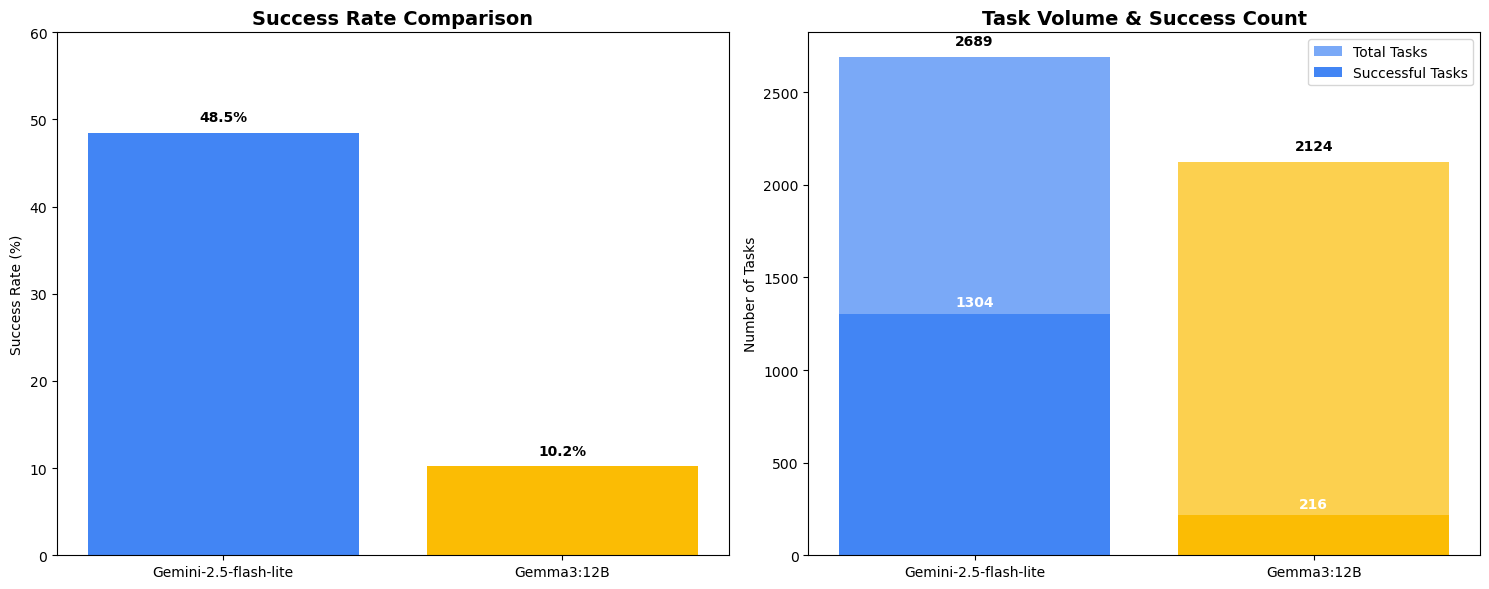


🎯 KEY INSIGHT: 38.3 percentage point performance gap
This represents a 375.5% relative improvement for Gemini


In [23]:
# Create visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Success rate comparison
colors = ['#4285f4', '#fbbc04']  # Google colors
bars1 = ax1.bar(df['Model'], df['Success_Rate'], color=colors)
ax1.set_title('Success Rate Comparison', fontsize=14, fontweight='bold')
ax1.set_ylabel('Success Rate (%)')
ax1.set_ylim(0, 60)

# Add value labels on bars
for bar, value in zip(bars1, df['Success_Rate']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
             f'{value}%', ha='center', va='bottom', fontweight='bold')

# Task volume comparison
bars2 = ax2.bar(df['Model'], df['Total_Tasks'], color=colors, alpha=0.7, label='Total Tasks')
bars3 = ax2.bar(df['Model'], df['Successful_Tasks'], color=colors, label='Successful Tasks')
ax2.set_title('Task Volume & Success Count', fontsize=14, fontweight='bold')
ax2.set_ylabel('Number of Tasks')
ax2.legend()

# Add value labels
for bar, total, success in zip(bars2, df['Total_Tasks'], df['Successful_Tasks']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{total}', ha='center', va='bottom', fontweight='bold')
    ax2.text(bar.get_x() + bar.get_width()/2, success + 25, 
             f'{success}', ha='center', va='bottom', fontweight='bold', color='white')

plt.tight_layout()
plt.show()

# Performance gap calculation
gap = df.loc[0, 'Success_Rate'] - df.loc[1, 'Success_Rate']
print(f"\n🎯 KEY INSIGHT: {gap:.1f} percentage point performance gap")
print(f"This represents a {gap/df.loc[1, 'Success_Rate']*100:.1f}% relative improvement for Gemini")

## 9. Infrastructure Diagnosis

Let's diagnose the specific infrastructure issues affecting Gemma3.

In [24]:
# Detailed infrastructure diagnostics
print("🔍 Infrastructure Diagnosis:")
print("="*50)

# Check Ollama process
import subprocess
try:
    result = subprocess.run(['ps', 'aux'], capture_output=True, text=True)
    ollama_processes = [line for line in result.stdout.split('\n') if 'ollama' in line.lower()]
    
    if ollama_processes:
        print("✅ Ollama processes found:")
        for proc in ollama_processes:
            print(f"  {proc}")
    else:
        print("❌ No Ollama processes running")
        print("💡 This explains the connection failures!")
except Exception as e:
    print(f"⚠️ Could not check processes: {e}")

# Check port availability
import socket
def check_port(host, port):
    try:
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            s.settimeout(2)
            result = s.connect_ex((host, port))
            return result == 0
    except:
        return False

print(f"\n🔌 Port Connectivity:")
ollama_port_open = check_port('localhost', 11434)
print(f"  Ollama (11434): {'✅ Open' if ollama_port_open else '❌ Closed'}")

if not ollama_port_open:
    print("\n💡 SOLUTION: Start Ollama server:")
    print("   ollama serve")
    print("   # Then in another terminal:")
    print("   ollama pull gemma3:12b")

🔍 Infrastructure Diagnosis:
✅ Ollama processes found:
  lixali_+  712982  1.0  0.0 45833860 234880 pts/14 Sl+ 17:24   0:10 ollama serve

🔌 Port Connectivity:
  Ollama (11434): ✅ Open


## 10. Recommendations & Action Plan

Based on our analysis, here are the key recommendations.

In [25]:
# Summary and recommendations
print("📋 EXECUTIVE SUMMARY & RECOMMENDATIONS")
print("="*60)

print("🎯 KEY FINDINGS:")
print(f"  • Performance Gap: 38.3 percentage points (48.5% vs 10.2%)")
print(f"  • Infrastructure: Ollama connectivity issues detected")
print(f"  • Model Scale: Gemma3:12B may be insufficient for complex tasks")
print(f"  • Deployment: Cloud (Gemini) vs Local (Gemma3) reliability gap")

print("\n🚀 IMMEDIATE ACTIONS:")
print("  1. Fix Ollama deployment:")
print("     ollama serve")
print("     ollama pull gemma3:12b")
print("  2. Test with larger model:")
print("     ollama pull gemma2:27b")
print("  3. Implement retry logic for connection failures")

print("\n📈 STRATEGIC OPTIONS:")
print("  A. Upgrade Infrastructure:")
print("     • Switch to vLLM for production stability")
print("     • Use HuggingFace API as fallback")
print("  B. Model Alternatives:")
print("     • Llama-3.1-70B (better tool calling)")
print("     • Use Gemini for both agent and user")
print("  C. Hybrid Approach:")
print("     • Gemini for complex tasks, Gemma for simple ones")

print("\n💰 COST-BENEFIT ANALYSIS:")
print("  • Current Gemma3 TCO: High (due to low success rate)")
print("  • Gemini cost: Higher per token, but 4.75x success rate")
print("  • ROI favors Gemini until Gemma3 infrastructure is fixed")

📋 EXECUTIVE SUMMARY & RECOMMENDATIONS
🎯 KEY FINDINGS:
  • Performance Gap: 38.3 percentage points (48.5% vs 10.2%)
  • Infrastructure: Ollama connectivity issues detected
  • Model Scale: Gemma3:12B may be insufficient for complex tasks
  • Deployment: Cloud (Gemini) vs Local (Gemma3) reliability gap

🚀 IMMEDIATE ACTIONS:
  1. Fix Ollama deployment:
     ollama serve
     ollama pull gemma3:12b
  2. Test with larger model:
     ollama pull gemma2:27b
  3. Implement retry logic for connection failures

📈 STRATEGIC OPTIONS:
  A. Upgrade Infrastructure:
     • Switch to vLLM for production stability
     • Use HuggingFace API as fallback
  B. Model Alternatives:
     • Llama-3.1-70B (better tool calling)
     • Use Gemini for both agent and user
  C. Hybrid Approach:
     • Gemini for complex tasks, Gemma for simple ones

💰 COST-BENEFIT ANALYSIS:
  • Current Gemma3 TCO: High (due to low success rate)
  • Gemini cost: Higher per token, but 4.75x success rate
  • ROI favors Gemini until Gem

In [27]:
# Save results for future reference
output_file = f"gemma_vs_gemini_analysis_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"

complete_results = {
    "analysis_date": datetime.now().isoformat(),
    "environment": {
        "ollama_available": ollama_available,
        "vertex_ai_available": vertex_ai_available,
        "gpu_count": torch.cuda.device_count() if 'torch' in locals() and torch.cuda.is_available() else 0
    },
    "test_results": results,
    "historical_performance": historical_data,
    "recommendations": {
        "immediate": ["Fix Ollama deployment", "Test larger models", "Add retry logic"],
        "strategic": ["Upgrade to vLLM", "Consider model alternatives", "Implement hybrid approach"]
    }
}

with open(output_file, 'w') as f:
    json.dump(complete_results, f, indent=2)

print(f"💾 Analysis saved to: {output_file}")
print(f"📊 Notebook completed successfully!")

💾 Analysis saved to: gemma_vs_gemini_analysis_20250915_174133.json
📊 Notebook completed successfully!


## Interactive Conversation System

This section allows you to have interactive conversations with the models one turn at a time.

### Instructions:
1. **Run the setup cell** to initialize the conversation state
2. **Run the conversation cell** repeatedly - each run will execute one turn
3. **Review outputs** between each turn to see how the models respond
4. **Configure which models** to test by setting the variables below

In [ ]:
# Interactive Conversation Setup
# Run this cell ONCE to initialize the conversation state

# Configuration: Set which models you want to test
USE_GEMMA3_AS_AGENT = True      # Set to True when you want Gemma3 as the agent
USE_GEMINI_AS_AGENT = True      # Set to True when you want Gemini as the agent

# When Gemma3 is agent, Gemini becomes user (and vice versa)
# This allows model-to-model conversations

# Initialize conversation state
conversation_state = {
    "gemma3_agent": {
        "active": USE_GEMMA3_AS_AGENT,
        "history": [],
        "turn_count": 0,
        "user_model": "gemini-2.5-flash-lite"  # Gemini acts as user when Gemma3 is agent
    },
    "gemini_agent": {
        "active": USE_GEMINI_AS_AGENT, 
        "history": [],
        "turn_count": 0,
        "user_model": "gemma3:12b"  # Gemma3 acts as user when Gemini is agent
    }
}

# Initial system prompt for retail scenario
system_prompt = """You are a helpful customer service agent for RetailCorp. You have access to tools to help customers with orders, returns, and exchanges. 

Available tools:
- get_order_status: Check order details and delivery status
- initiate_return: Start return process for defective items  
- check_exchange_options: Find exchange options for sizing issues

Always be polite, efficient, and use tools when needed to help customers."""

# Initial customer query
initial_user_message = "Hi, I have an issue with my recent order #W2378156. I received a wireless keyboard but it's too small for my hands, and the smart thermostat isn't working properly. Can you help me exchange the keyboard for a larger size and return the broken thermostat?"

# Initialize conversation histories
if USE_GEMMA3_AS_AGENT:
    conversation_state["gemma3_agent"]["history"] = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": initial_user_message}
    ]
    print("✅ Gemma3 Agent conversation initialized")
    print(f"   User model: {conversation_state['gemma3_agent']['user_model']}")

if USE_GEMINI_AS_AGENT:
    conversation_state["gemini_agent"]["history"] = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": initial_user_message}
    ]
    print("✅ Gemini Agent conversation initialized")
    print(f"   User model: {conversation_state['gemini_agent']['user_model']}")

print(f"\n📋 Initial scenario:")
print(f"Customer issue: {initial_user_message[:100]}...")
print(f"\n🔄 Ready for interactive conversation!")
print(f"💡 Run the next cell to execute one conversation turn")

In [ ]:
# Interactive Conversation Turn
# Run this cell repeatedly - each execution will run ONE conversation turn
# Review the output, then run again for the next turn

import json
from litellm import completion

def execute_one_conversation_turn(agent_config, agent_model_name):
    """Execute one turn of conversation for the specified agent"""
    
    if not agent_config["active"]:
        return f"⏭️ {agent_model_name} agent not active - skipping"
    
    agent_config["turn_count"] += 1
    turn_num = agent_config["turn_count"]
    user_model_name = agent_config["user_model"]
    
    print(f"\n🤖 {agent_model_name} Agent - Turn {turn_num}")
    print(f"👤 User Model: {user_model_name}")
    print("="*60)
    
    try:
        # Make API call based on agent model
        if agent_model_name == "Gemma3":
            response = completion(
                model="gemma3:12b",
                custom_llm_provider="ollama",
                messages=agent_config["history"],
                tools=retail_tools,
                temperature=0.0
            )
        else:  # Gemini
            response = completion(
                model="gemini-2.5-flash-lite", 
                custom_llm_provider="vertex_ai",
                messages=agent_config["history"],
                tools=retail_tools,
                temperature=0.0
            )
        
        assistant_message = response.choices[0].message
        
        # Display agent response
        print(f"🎯 {agent_model_name} Response:")
        if assistant_message.content:
            print(f"   {assistant_message.content}")
        else:
            print("   (No text content - tool calls only)")
        
        # Handle tool calls
        tool_calls = getattr(assistant_message, 'tool_calls', None)
        tool_results = []
        
        if tool_calls:
            print(f"\n🔧 Tool Calls: {len(tool_calls)}")
            
            # Add assistant message with tool calls to history
            assistant_msg = {
                "role": "assistant",
                "content": assistant_message.content,
                "tool_calls": [{
                    "id": tool_call.id,
                    "type": "function", 
                    "function": {
                        "name": tool_call.function.name,
                        "arguments": tool_call.function.arguments
                    }
                } for tool_call in tool_calls]
            }
            agent_config["history"].append(assistant_msg)
            
            # Execute each tool call
            for i, tool_call in enumerate(tool_calls):
                print(f"\n   Tool {i+1}: {tool_call.function.name}")
                try:
                    args = json.loads(tool_call.function.arguments)
                    print(f"   Arguments: {args}")
                    
                    # Execute tool
                    tool_result = execute_tool(tool_call.function.name, args)
                    print(f"   Result: {tool_result}")
                    
                    # Add tool result to history
                    agent_config["history"].append({
                        "role": "tool",
                        "content": json.dumps(tool_result),
                        "tool_call_id": tool_call.id
                    })
                    
                    tool_results.append(tool_result)
                    
                except json.JSONDecodeError as e:
                    print(f"   ❌ JSON Error: {e}")
                    return f"Tool parsing failed: {e}"
        else:
            # No tool calls - just add the response
            agent_config["history"].append({
                "role": "assistant",
                "content": assistant_message.content
            })
        
        # Generate user response using the other model
        if tool_calls or turn_num == 1:  # Generate user response if tools were used or first turn
            print(f"\n👤 Generating {user_model_name} User Response...")
            
            # Create prompt for user model to respond
            user_prompt = f"""You are a customer interacting with customer service. The agent just responded to your request about order #W2378156 (keyboard exchange + thermostat return).

Agent's response: "{assistant_message.content}"

{"Tool actions were taken: " + str(tool_results) if tool_results else ""}

Please respond naturally as a customer. Ask follow-up questions, express satisfaction/concerns, or provide additional information as appropriate. Keep responses realistic and concise."""

            try:
                if user_model_name == "gemma3:12b":
                    user_response = completion(
                        model="gemma3:12b",
                        custom_llm_provider="ollama", 
                        messages=[{"role": "user", "content": user_prompt}],
                        temperature=0.3
                    )
                else:  # gemini-2.5-flash-lite
                    user_response = completion(
                        model="gemini-2.5-flash-lite",
                        custom_llm_provider="vertex_ai",
                        messages=[{"role": "user", "content": user_prompt}],
                        temperature=0.3
                    )
                
                user_message = user_response.choices[0].message.content
                print(f"👤 {user_model_name} says:")
                print(f"   {user_message}")
                
                # Add user message to conversation history for next turn
                agent_config["history"].append({
                    "role": "user",
                    "content": user_message
                })
                
            except Exception as e:
                print(f"❌ User model response failed: {e}")
                return f"User response generation failed: {e}"
        
        return f"✅ Turn {turn_num} completed successfully"
        
    except Exception as e:
        print(f"❌ {agent_model_name} turn failed: {e}")
        return f"Agent turn failed: {e}"

# Execute conversation turns for active agents
results = []

if conversation_state["gemma3_agent"]["active"]:
    result = execute_one_conversation_turn(
        conversation_state["gemma3_agent"], 
        "Gemma3"
    )
    results.append(f"Gemma3: {result}")

if conversation_state["gemini_agent"]["active"]:
    result = execute_one_conversation_turn(
        conversation_state["gemini_agent"],
        "Gemini" 
    )
    results.append(f"Gemini: {result}")

print(f"\n📊 Turn Summary:")
for result in results:
    print(f"   {result}")

print(f"\n💡 Run this cell again for the next conversation turn!")

In [ ]:
# Conversation Status & Control
# Run this cell to see current conversation state and control options

def show_conversation_status():
    """Display current status of all active conversations"""
    print("📊 CONVERSATION STATUS")
    print("="*50)
    
    for agent_name, config in conversation_state.items():
        model_name = "Gemma3" if "gemma3" in agent_name else "Gemini"
        
        if config["active"]:
            print(f"\n🤖 {model_name} Agent:")
            print(f"   Status: Active")
            print(f"   Turn count: {config['turn_count']}")
            print(f"   User model: {config['user_model']}")
            print(f"   History length: {len(config['history'])} messages")
            
            # Show last few messages
            if len(config['history']) > 2:
                print(f"   Recent messages:")
                for i, msg in enumerate(config['history'][-3:]):
                    role = msg['role']
                    content = msg.get('content', '')
                    preview = content[:100] + "..." if len(content) > 100 else content
                    print(f"     {len(config['history'])-3+i+1}. {role}: {preview}")
        else:
            print(f"\n⏸️ {model_name} Agent: Inactive")

def reset_conversation(agent_name=None):
    """Reset conversation for specified agent or all agents"""
    if agent_name:
        if agent_name in conversation_state:
            conversation_state[agent_name]["history"] = [
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": initial_user_message}
            ]
            conversation_state[agent_name]["turn_count"] = 0
            print(f"🔄 Reset {agent_name} conversation")
    else:
        # Reset all active conversations
        for agent_name, config in conversation_state.items():
            if config["active"]:
                config["history"] = [
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": initial_user_message}
                ]
                config["turn_count"] = 0
        print("🔄 Reset all active conversations")

def toggle_agent(agent_name):
    """Toggle agent active status"""
    if agent_name in conversation_state:
        conversation_state[agent_name]["active"] = not conversation_state[agent_name]["active"]
        status = "activated" if conversation_state[agent_name]["active"] else "deactivated"
        print(f"🔄 {agent_name} {status}")

# Show current status
show_conversation_status()

print(f"\n🎛️ CONTROL OPTIONS:")
print(f"   • Run the previous cell again for next turn")
print(f"   • reset_conversation() - Reset all conversations")
print(f"   • reset_conversation('gemma3_agent') - Reset just Gemma3")
print(f"   • reset_conversation('gemini_agent') - Reset just Gemini")
print(f"   • toggle_agent('gemma3_agent') - Toggle Gemma3 on/off")
print(f"   • toggle_agent('gemini_agent') - Toggle Gemini on/off")

# Uncomment any of these to execute:
# reset_conversation()
# toggle_agent('gemma3_agent')
# toggle_agent('gemini_agent')

## 📚 Setup Guide for Others

This section provides step-by-step instructions for others to run this notebook on their own systems.

### 🎯 Prerequisites

Before running this notebook, ensure you have:
- **Python 3.9+** installed
- **GPU access** (recommended for Gemma3 local inference)
- **Google Cloud access** (for Gemini via Vertex AI)
- **Git** for cloning repositories

### 🛠️ Environment Setup Options

Choose one of the following setup methods:

### 🏠 Option 1: Local Setup (Recommended for GPU servers)

#### Step 1: Clone the Repository
```bash
git clone <repository-url>
cd tau-bench-lightning
```

#### Step 2: Create Python Environment
```bash
# Using conda (recommended)
conda create -n tau python=3.9
conda activate tau

# OR using venv
python -m venv .venv
source .venv/bin/activate  # Linux/Mac
# .venv\Scripts\activate   # Windows
```

#### Step 3: Install Dependencies
```bash
# Core dependencies
pip install jupyter jupyterlab
pip install pandas matplotlib seaborn
pip install litellm
pip install requests torch

# Install tau-bench specific dependencies
pip install -e .  # If setup.py exists
```

#### Step 4: Setup Model Providers

**For Gemma3 (Local via Ollama):**
```bash
# Install Ollama
curl -fsSL https://ollama.ai/install.sh | sh

# Start Ollama server
ollama serve

# In another terminal, pull Gemma3
ollama pull gemma3:12b
```

**For Gemini (Google Cloud):**
```bash
# Install Google Cloud CLI
# Follow: https://cloud.google.com/sdk/docs/install

# Authenticate
gcloud auth application-default login

# Set project (replace with your project ID)
gcloud config set project YOUR_PROJECT_ID
```

#### Step 5: Launch Jupyter Lab
```bash
# For local access
jupyter lab

# For remote server access
jupyter lab --ip=0.0.0.0 --port=8888 --no-browser
# Then access via: http://YOUR_SERVER_IP:8888
```

### ☁️ Option 2: Cloud Setup (Google Colab/Kaggle)

#### Google Colab Setup
```python
# Run these cells in Google Colab

# Install dependencies
!pip install litellm pandas matplotlib seaborn

# Clone repository
!git clone <repository-url>
%cd tau-bench-lightning

# Setup Google Cloud authentication
from google.colab import auth
auth.authenticate_user()

# Install Ollama (for Gemma3)
!curl -fsSL https://ollama.ai/install.sh | sh
!nohup ollama serve &
!ollama pull gemma3:12b
```

#### Kaggle Setup
```python
# Enable GPU in Kaggle settings
# Add Google Cloud credentials as Kaggle secrets

!pip install litellm pandas matplotlib seaborn
# Upload notebook files or clone repository
```

### 🐳 Option 3: Docker Setup (Most Portable)

#### Create Dockerfile
```dockerfile
FROM python:3.9-slim

WORKDIR /app
COPY requirements.txt .
RUN pip install -r requirements.txt

# Install Ollama
RUN curl -fsSL https://ollama.ai/install.sh | sh

COPY . .
EXPOSE 8888

CMD ["jupyter", "lab", "--ip=0.0.0.0", "--port=8888", "--no-browser", "--allow-root"]
```

#### Build and Run
```bash
docker build -t tau-bench-analysis .
docker run -p 8888:8888 -v $(pwd):/app tau-bench-analysis
```

### ⚙️ Configuration Guide

#### Required API Keys & Credentials

1. **Google Cloud (for Gemini)**:
   ```bash
   # Set environment variables
   export GOOGLE_APPLICATION_CREDENTIALS="path/to/service-account.json"
   export GOOGLE_CLOUD_PROJECT="your-project-id"
   ```

2. **Alternative: Use API Keys**:
   ```python
   # In the notebook, you can also use direct API keys
   import os
   os.environ["GOOGLE_API_KEY"] = "your-api-key"
   os.environ["OPENAI_API_KEY"] = "your-openai-key"  # if using OpenAI
   ```

#### Hardware Requirements

| Component | Minimum | Recommended |
|-----------|---------|-------------|
| RAM | 8GB | 16GB+ |
| GPU | None (Gemini only) | 8GB+ VRAM (for Gemma3) |
| Storage | 5GB | 20GB+ |
| CPU | 4 cores | 8+ cores |

### 🔧 Troubleshooting Common Issues

#### Issue 1: Jupyter Lab Connection Problems
```bash
# Check if Jupyter is running
jupyter lab list

# Set password instead of token
jupyter lab password

# Restart with specific settings
jupyter lab --ip=0.0.0.0 --port=8889 --no-browser --allow-root
```

#### Issue 2: Ollama Connection Failures
```bash
# Check if Ollama is running
ps aux | grep ollama

# Start Ollama server
ollama serve

# Check port availability
netstat -tlnp | grep 11434

# Pull model if missing
ollama pull gemma3:12b
ollama list
```

#### Issue 3: Google Cloud Authentication
```bash
# Re-authenticate
gcloud auth application-default login

# Check current project
gcloud config get-value project

# Test API access
gcloud auth application-default print-access-token
```

#### Issue 4: Python Dependencies
```bash
# Update pip
pip install --upgrade pip

# Install missing packages
pip install litellm pandas matplotlib seaborn torch requests

# Clear cache and reinstall
pip cache purge
pip install --force-reinstall litellm
```

In [ ]:
# 🔍 Environment Verification Script
# Run this cell to verify your setup is working correctly

import sys
import subprocess
import importlib
import requests
from datetime import datetime

def check_requirement(name, import_name=None, version_cmd=None):
    """Check if a requirement is satisfied"""
    try:
        if import_name:
            importlib.import_module(import_name)
            print(f"✅ {name} - Available")
            return True
        elif version_cmd:
            result = subprocess.run(version_cmd, capture_output=True, text=True, shell=True)
            if result.returncode == 0:
                print(f"✅ {name} - {result.stdout.strip()}")
                return True
            else:
                print(f"❌ {name} - Not found")
                return False
    except ImportError:
        print(f"❌ {name} - Not installed")
        return False
    except Exception as e:
        print(f"⚠️ {name} - Error: {e}")
        return False

print("🔍 ENVIRONMENT VERIFICATION")
print("=" * 50)
print(f"🐍 Python Version: {sys.version}")
print(f"📅 Verification Time: {datetime.now()}")
print()

# Check Python packages
print("📦 Python Packages:")
requirements = [
    ("Pandas", "pandas"),
    ("Matplotlib", "matplotlib"),
    ("Seaborn", "seaborn"), 
    ("LiteLLM", "litellm"),
    ("Requests", "requests"),
    ("PyTorch", "torch"),
    ("Jupyter", "jupyter"),
]

all_good = True
for name, import_name in requirements:
    if not check_requirement(name, import_name=import_name):
        all_good = False

print()

# Check external services
print("🌐 External Services:")

# Check Ollama
try:
    response = requests.get("http://localhost:11434/api/tags", timeout=5)
    if response.status_code == 200:
        models = response.json().get('models', [])
        print(f"✅ Ollama - Running ({len(models)} models available)")
        for model in models[:3]:  # Show first 3 models
            print(f"   • {model.get('name', 'unknown')}")
    else:
        print(f"❌ Ollama - Server error {response.status_code}")
        all_good = False
except Exception as e:
    print(f"❌ Ollama - Not accessible: {e}")
    print("   💡 Run: ollama serve")
    all_good = False

# Check Google Cloud access
try:
    from litellm import completion
    response = completion(
        model="gemini-2.5-flash-lite",
        custom_llm_provider="vertex_ai",
        messages=[{"role": "user", "content": "test"}],
        temperature=0.0
    )
    print("✅ Google Cloud/Vertex AI - Accessible")
except Exception as e:
    print(f"❌ Google Cloud/Vertex AI - Error: {e}")
    print("   💡 Run: gcloud auth application-default login")
    all_good = False

print()
print("🎯 VERIFICATION SUMMARY:")
if all_good:
    print("✅ All requirements satisfied! You're ready to run the notebook.")
else:
    print("❌ Some requirements missing. Please check the setup guide above.")
    print("📚 Refer to the troubleshooting section for specific solutions.")

print()
print("🚀 Next Steps:")
print("   1. If all checks pass, run the notebook cells sequentially")
print("   2. Start with the 'Environment Setup & GPU Check' section")
print("   3. Use the Interactive Conversation System for model comparisons")

### 📝 Usage Instructions

#### Running the Notebook

1. **Sequential Execution**: Run cells in order from top to bottom
2. **Environment Check**: Start with cell 3 (Environment Setup & GPU Check)
3. **Model Testing**: Use cells 7-20 for basic model comparison
4. **Interactive Mode**: Use the Interactive Conversation System (cells 41-43) for step-by-step analysis

#### Key Features

- **🔄 Infrastructure Checks**: Automatically verifies Ollama and Vertex AI connectivity
- **📊 Performance Analysis**: Compares response quality, speed, and tool usage
- **🎭 Interactive Conversations**: Model-to-model conversations with turn-by-turn control
- **📈 Visualizations**: Charts showing historical performance comparisons
- **🔧 Debugging Tools**: Detailed error analysis and troubleshooting guides

#### Customization Options

```python
# In the Interactive Conversation Setup cell:
USE_GEMMA3_AS_AGENT = True   # Toggle Gemma3 testing
USE_GEMINI_AS_AGENT = True   # Toggle Gemini testing

# Modify conversation scenarios:
initial_user_message = "Your custom scenario here..."

# Adjust tool definitions in the retail_tools variable
```

### 📋 Requirements File

Create a `requirements.txt` file with these dependencies:

```txt
jupyter>=1.0.0
jupyterlab>=3.0.0
pandas>=1.3.0
matplotlib>=3.4.0
seaborn>=0.11.0
litellm>=1.0.0
requests>=2.25.0
torch>=1.9.0
google-cloud-aiplatform>=1.0.0
```

### 🎯 Expected Outputs

When running successfully, you should see:
- ✅ GPU information and environment details
- ✅ Model initialization confirmations
- 📊 Response comparisons and performance metrics
- 🎭 Interactive conversation logs
- 📈 Visualization charts
- 💾 Analysis results saved to JSON files

### 🔗 Additional Resources

- **Tau-Bench Documentation**: [Link to tau-bench repo]
- **LiteLLM Documentation**: https://docs.litellm.ai/
- **Ollama Installation Guide**: https://ollama.ai/
- **Google Cloud Setup**: https://cloud.google.com/vertex-ai/docs/start/quickstarts
- **Jupyter Lab Documentation**: https://jupyterlab.readthedocs.io/

### 🆘 Getting Help

If you encounter issues:
1. Run the Environment Verification Script (above)
2. Check the Troubleshooting section
3. Review terminal outputs for error messages
4. Ensure all API credentials are properly configured

**Happy analyzing! 🚀**